In [1]:
from datasets import load_dataset

DATASET_NAME = "BioLaySumm/BioLaySumm2025-eLife"
SEED = 42

dataset = load_dataset(
    DATASET_NAME,
    streaming=True
)

print("Dataset splits:", list(dataset.keys()))

for split in dataset:
    print(f"\n{split.upper()}")
    print("Columns:", dataset[split].column_names)
    print("Features:", dataset[split].features)

/home/pasali/anaconda3/envs/myenv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset splits: ['train', 'validation', 'test']

TRAIN
Columns: ['article', 'summary', 'section_headings', 'keywords', 'year', 'title']
Features: {'article': Value('string'), 'summary': Value('string'), 'section_headings': List(Value('string')), 'keywords': List(Value('string')), 'year': Value('string'), 'title': Value('string')}

VALIDATION
Columns: ['article', 'summary', 'section_headings', 'keywords', 'year', 'title']
Features: {'article': Value('string'), 'summary': Value('string'), 'section_headings': List(Value('string')), 'keywords': List(Value('string')), 'year': Value('string'), 'title': Value('string')}

TEST
Columns: ['article', 'summary', 'section_headings', 'keywords', 'year', 'title']
Features: {'article': Value('string'), 'summary': Value('string'), 'section_headings': List(Value('string')), 'keywords': List(Value('string')), 'year': Value('string'), 'title': Value('string')}


In [2]:
from datasets import Dataset, DatasetDict

sample_sizes = {
    "train": 500,
    "validation": 100,
    "test": 100
}

sampled_dataset = DatasetDict()

for split, size in sample_sizes.items():
    shuffled = dataset[split].shuffle(
        seed=SEED,
        buffer_size=1000
    )

    samples = list(shuffled.take(size))
    sampled_dataset[split] = Dataset.from_list(samples)

    print(f"{split}: {len(sampled_dataset[split])} samples")

train: 500 samples
validation: 100 samples
test: 100 samples


In [3]:
import pandas as pd

def is_missing(value):
    if value is None:
        return True
    if isinstance(value, str):
        return not value.strip()
    if isinstance(value, (list, tuple)):
        return len(value) == 0
    return False

for split, ds in sampled_dataset.items():
    missing_counts = {
        col: sum(is_missing(value) for value in ds[col])
        for col in ds.column_names
    }

    print(f"\n{split.upper()} | Total samples: {len(ds)}")
    print(pd.Series(missing_counts))


TRAIN | Total samples: 500
article             0
summary             0
section_headings    0
keywords            0
year                0
title               0
dtype: int64

VALIDATION | Total samples: 100
article             0
summary             0
section_headings    0
keywords            0
year                0
title               0
dtype: int64

TEST | Total samples: 100
article               0
summary             100
section_headings      0
keywords              0
year                100
title               100
dtype: int64


In [4]:
length_stats = []

for split, ds in sampled_dataset.items():
    for column in ["article", "summary"]:
        texts = [
            text for text in ds[column]
            if isinstance(text, str) and text.strip()
        ]

        if not texts:
            continue

        word_lengths = pd.Series(
            [len(text.split()) for text in texts]
        )

        length_stats.append({
            "split": split,
            "column": column,
            "count": len(texts),
            "mean": round(word_lengths.mean(), 2),
            "median": word_lengths.median(),
            "p90": word_lengths.quantile(0.90),
            "max": word_lengths.max()
        })

length_df = pd.DataFrame(length_stats)

display(length_df)

,split,column,count,mean,median,p90,max
0,train,article,500,10008.12,9747.5,14358.3,28696
1,train,summary,500,381.72,376.5,469.0,580
2,validation,article,100,9847.24,9465.0,14978.1,23048
3,validation,summary,100,387.93,382.5,486.3,540
4,test,article,100,7875.43,7898.5,11443.9,13369


In [ ]:
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("google/flan-t5-base")

articles = sampled_dataset["train"]["article"][:100]
summaries = sampled_dataset["train"]["summary"][:100]

article_tokens = [
    len(tokenizer.encode(text, truncation=False))
    for text in articles
]

summary_tokens = [
    len(tokenizer.encode(text, truncation=False))
    for text in summaries
]

token_stats = pd.DataFrame({
    "article_tokens": article_tokens,
    "summary_tokens": summary_tokens
})

display(token_stats.describe(percentiles=[0.5, 0.9, 0.95]))

print("Articles exceeding 512 tokens:", sum(token_stats["article_tokens"] > 512))
print("Articles exceeding 1024 tokens:", sum(token_stats["article_tokens"] > 1024))
print("Summaries exceeding 512 tokens:", sum(token_stats["summary_tokens"] > 512))

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (10631 > 512). Running this sequence through the model will result in indexing errors


,article_tokens,summary_tokens
count,100.000000,100.000000
mean,17173.650000,509.360000
std,5799.950176,98.879737
min,6016.000000,309.000000
50%,16372.000000,509.000000
90%,25559.600000,623.200000
95%,26508.000000,692.000000
max,37872.000000,837.000000


Articles exceeding 512 tokens: 100
Articles exceeding 1024 tokens: 100
Summaries exceeding 512 tokens: 47


In [6]:
from huggingface_hub import HfApi, hf_hub_download
from pathlib import Path

api = HfApi()

dataset_info = api.dataset_info(DATASET_NAME)

print("Dataset:", dataset_info.id)
print("Revision:", dataset_info.sha)
print("License:", getattr(dataset_info.card_data, "license", None))

readme_path = hf_hub_download(
    repo_id=DATASET_NAME,
    filename="README.md",
    repo_type="dataset"
)

readme = Path(readme_path).read_text(encoding="utf-8")

print("\nDataset README:")
print(readme[:3000])

Dataset: BioLaySumm/BioLaySumm2025-eLife
Revision: 144e9c785e3a309da804eb6786feb38e6596f390
License: None

Dataset README:
---
dataset_info:
  features:
  - name: article
    dtype: string
  - name: summary
    dtype: string
  - name: section_headings
    sequence: string
  - name: keywords
    sequence: string
  - name: year
    dtype: string
  - name: title
    dtype: string
  splits:
  - name: train
    num_bytes: 261153608
    num_examples: 4346
  - name: validation
    num_bytes: 14265606
    num_examples: 241
  - name: test
    num_bytes: 6613761
    num_examples: 142
  download_size: 136295683
  dataset_size: 282032975
configs:
- config_name: default
  data_files:
  - split: train
    path: data/train-*
  - split: validation
    path: data/validation-*
  - split: test
    path: data/test-*
---



In [7]:
import json
from pathlib import Path

project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

data_dir = project_dir / "data"
data_dir.mkdir(parents=True, exist_ok=True)

dataset_path = data_dir / "healthbrief_sampled"

sampled_dataset.save_to_disk(str(dataset_path))

metadata = {
    "dataset": DATASET_NAME,
    "revision": dataset_info.sha,
    "seed": SEED,
    "sampling_method": "streaming_buffer_shuffle",
    "buffer_size": 1000,
    "sample_sizes": sample_sizes,
    "license": getattr(dataset_info.card_data, "license", None),
    "test_references_available": False
}

with open(data_dir / "dataset_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=4, ensure_ascii=False)

print("Dataset saved:", dataset_path)
print("Metadata saved:", data_dir / "dataset_metadata.json")

Saving the dataset (1/1 shards): 100%|██████████| 100/100 [00:00<00:00, 20014.81 examples/s]

Dataset saved: /home/pasali/Desktop/Data/AI-Engineer/Hafta-7/HealthBrief/data/healthbrief_sampled
Metadata saved: /home/pasali/Desktop/Data/AI-Engineer/Hafta-7/HealthBrief/data/dataset_metadata.json


In [8]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from datasets import load_from_disk
from transformers import AutoTokenizer

project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

data_dir = project_dir / "data"
reports_dir = project_dir / "reports"
figures_dir = project_dir / "figures"

reports_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

if "sampled_dataset" not in globals():
    sampled_dataset = load_from_disk(
        str(data_dir / "healthbrief_sampled")
    )

if "tokenizer" not in globals():
    tokenizer = AutoTokenizer.from_pretrained(
        "google/flan-t5-base"
    )

train_df = sampled_dataset["train"].to_pandas()
validation_df = sampled_dataset["validation"].to_pandas()

train_df["split"] = "train"
validation_df["split"] = "validation"

df = pd.concat(
    [train_df, validation_df],
    ignore_index=True
)

print("Train:", len(train_df))
print("Validation:", len(validation_df))
print("Total:", len(df))

display(df.head(3))

Train: 500
Validation: 100
Total: 600


,article,summary,section_headings,keywords,year,title,split
0,How long neural information is stored in a loc...,Autism is a brain disorder that affects how pe...,"[Abstract, Introduction, Results, Discussion, ...",[neuroscience],2019,Atypical intrinsic neural timescale in autism,train
1,Breathing is a vital rhythmic behavior generat...,Babies need to start breathing immediately whe...,"[Abstract, Introduction, Results, Discussion, ...",[neuroscience],2016,Development of pacemaker properties and rhythm...,train
2,Reconstructing the lineage of cells is central...,"Our ears , eyes and other sensory organs colle...","[Abstract, Introduction, Results, Discussion, ...","[developmental, biology, cell, biology]",2017,Distribution of neurosensory progenitor pools ...,train


In [9]:
import re

def is_missing(value):
    if value is None:
        return True

    if isinstance(value, (float, np.floating)):
        return bool(pd.isna(value))

    return False


def is_empty(value):
    if isinstance(value, str):
        return len(value.strip()) == 0

    if isinstance(value, (list, tuple, np.ndarray)):
        return len(value) == 0

    return False


def normalize_text(value):
    if not isinstance(value, str):
        return None

    normalized = re.sub(r"\s+", " ", value.strip()).casefold()

    return normalized if normalized else None


columns = [
    "article",
    "summary",
    "title",
    "year",
    "keywords",
    "section_headings"
]

quality_results = []

for split in ["train", "validation"]:
    subset = df[df["split"] == split]

    article_normalized = subset["article"].map(normalize_text)
    title_normalized = subset["title"].map(normalize_text)

    result = {
        "split": split,
        "total_samples": len(subset)
    }

    for column in columns:
        result[f"{column}_missing"] = int(
            subset[column].map(is_missing).sum()
        )

        result[f"{column}_empty"] = int(
            subset[column].map(is_empty).sum()
        )

    result["duplicate_articles"] = int(
        article_normalized.dropna().duplicated().sum()
    )

    result["duplicate_titles"] = int(
        title_normalized.dropna().duplicated().sum()
    )

    quality_results.append(result)

quality_df = pd.DataFrame(quality_results)

display(quality_df.T)

,0,1
split,train,validation
total_samples,500,100
article_missing,0,0
article_empty,0,0
summary_missing,0,0
summary_empty,0,0
title_missing,0,0
title_empty,0,0
year_missing,0,0
year_empty,0,0


In [10]:
train_articles = set(
    train_df["article"]
    .map(normalize_text)
    .dropna()
)

validation_articles = set(
    validation_df["article"]
    .map(normalize_text)
    .dropna()
)

train_titles = set(
    train_df["title"]
    .map(normalize_text)
    .dropna()
)

validation_titles = set(
    validation_df["title"]
    .map(normalize_text)
    .dropna()
)

article_overlap = train_articles.intersection(
    validation_articles
)

title_overlap = train_titles.intersection(
    validation_titles
)

print("Article overlap:", len(article_overlap))
print("Title overlap:", len(title_overlap))

quality_df["article_overlap"] = len(article_overlap)
quality_df["title_overlap"] = len(title_overlap)

if len(article_overlap) > 0:
    print("WARNING: Duplicate articles across splits detected.")

if len(title_overlap) > 0:
    print("WARNING: Duplicate titles across splits detected.")

Article overlap: 0
Title overlap: 0


In [11]:
for column in ["article", "summary"]:
    df[f"{column}_words"] = df[column].apply(
        lambda text: len(text.split())
        if isinstance(text, str) and text.strip()
        else np.nan
    )

    texts = df[column].tolist()

    token_lengths = []

    for start in range(0, len(texts), 16):
        batch = texts[start:start + 16]

        batch = [
            text if isinstance(text, str) else ""
            for text in batch
        ]

        encoded = tokenizer(
            batch,
            truncation=False,
            padding=False,
            return_attention_mask=False,
            verbose=False
        )

        token_lengths.extend([
            len(ids) if text.strip() else np.nan
            for text, ids in zip(batch, encoded["input_ids"])
        ])

    df[f"{column}_tokens"] = token_lengths

df["compression_ratio"] = (
    df["article_words"] /
    df["summary_words"].replace(0, np.nan)
)

display(
    df[
        [
            "split",
            "article_words",
            "summary_words",
            "article_tokens",
            "summary_tokens",
            "compression_ratio"
        ]
    ].head(10)
)

,split,article_words,summary_words,article_tokens,summary_tokens,compression_ratio
0,train,6866,387,10631,466,17.741602
1,train,8735,286,13886,349,30.541958
2,train,10659,272,18949,346,39.187500
3,train,8658,462,13613,625,18.740260
4,train,8958,323,13311,421,27.733746
5,train,3493,523,6016,837,6.678776
6,train,6088,463,9336,614,13.149028
7,train,15701,333,25583,442,47.150150
8,train,13808,362,24594,525,38.143646
9,train,13934,322,26279,405,43.273292


In [13]:
length_results = []

for split in ["train", "validation"]:
    subset = df[df["split"] == split]

    for column in ["article", "summary"]:
        words = subset[f"{column}_words"].dropna()
        tokens = subset[f"{column}_tokens"].dropna()

        length_results.append({
            "split": split,
            "column": column,
            "count": len(words),
            "min_word_count": int(words.min()),
            "mean_word_count": round(words.mean(), 2),
            "max_word_count": int(words.max()),
            "p50_token_count": round(tokens.quantile(0.50), 2),
            "p95_token_count": round(tokens.quantile(0.95), 2),
            "p99_token_count": round(tokens.quantile(0.99), 2)
        })

length_statistics = pd.DataFrame(length_results)

compression_stats = (
    df.groupby("split")["compression_ratio"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

for split in ["train", "validation"]:
    mask = quality_df["split"] == split
    ratios = df.loc[
        df["split"] == split,
        "compression_ratio"
    ].dropna()

    quality_df.loc[
        mask, "compression_ratio_mean"
    ] = round(ratios.mean(), 2)

    quality_df.loc[
        mask, "compression_ratio_median"
    ] = round(ratios.median(), 2)

    quality_df.loc[
        mask, "compression_ratio_p95"
    ] = round(ratios.quantile(0.95), 2)

print("LENGTH STATISTICS")
display(length_statistics)

print("\nCOMPRESSION STATISTICS")
display(compression_stats)


LENGTH STATISTICS


,split,column,count,min_word_count,mean_word_count,max_word_count,p50_token_count,p95_token_count,p99_token_count
0,train,article,500,2474,10008.12,28696,16272.0,27737.45,33191.25
1,train,summary,500,204,381.72,580,519.0,688.15,760.05
2,validation,article,100,3408,9847.24,23048,15754.0,27568.25,30393.81
3,validation,summary,100,234,387.93,540,508.5,691.10,744.15



COMPRESSION STATISTICS


,count,mean,median,min,max
split,,,,,
train,500,27.02,25.43,6.22,71.44
validation,100,26.23,24.28,8.05,61.10


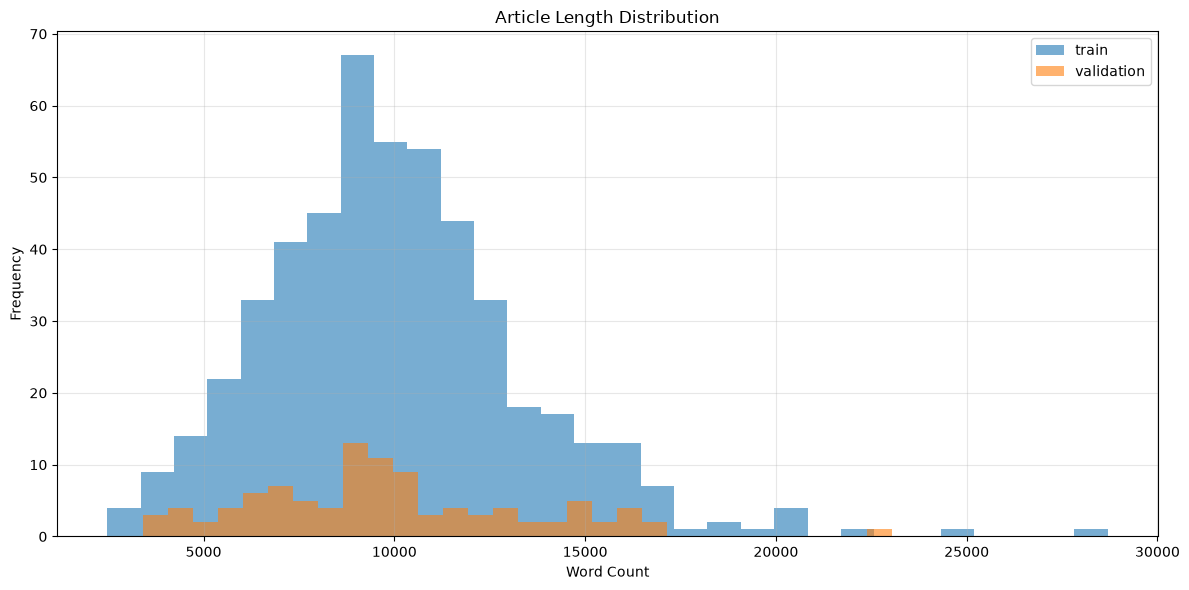

In [14]:
plt.figure(figsize=(12, 6))

for split in ["train", "validation"]:
    values = df.loc[
        df["split"] == split,
        "article_words"
    ].dropna()

    plt.hist(
        values,
        bins=30,
        alpha=0.6,
        label=split
    )

plt.title("Article Length Distribution")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "article_length_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

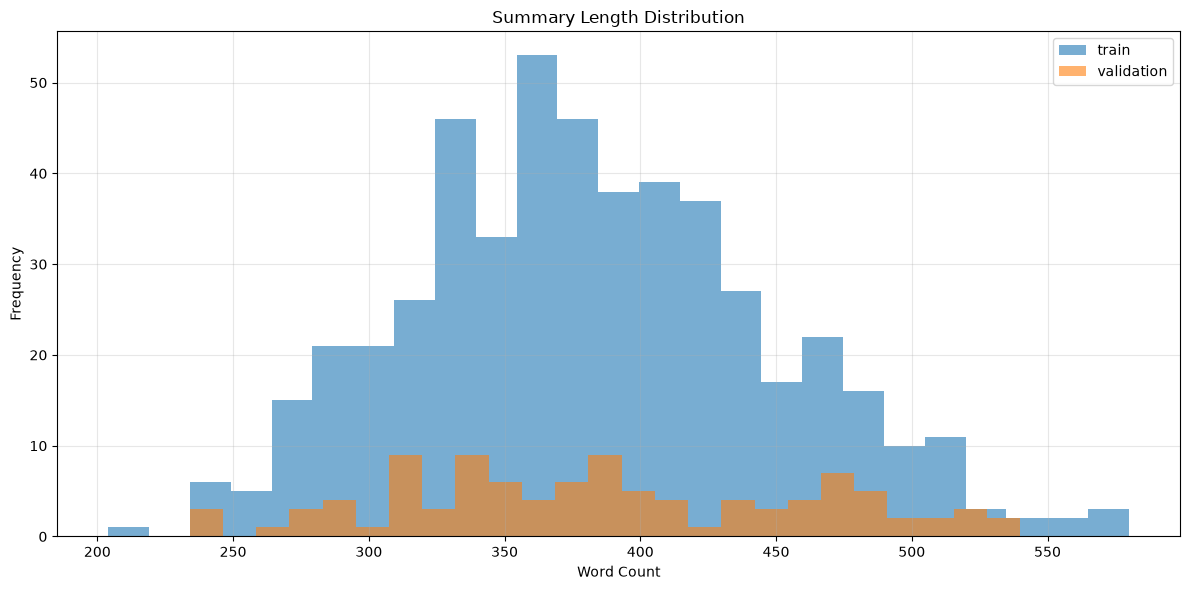

In [15]:
plt.figure(figsize=(12, 6))

for split in ["train", "validation"]:
    values = df.loc[
        df["split"] == split,
        "summary_words"
    ].dropna()

    plt.hist(
        values,
        bins=25,
        alpha=0.6,
        label=split
    )

plt.title("Summary Length Distribution")
plt.xlabel("Word Count")
plt.ylabel("Frequency")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    figures_dir / "summary_length_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
quality_df.to_csv(
    reports_dir / "data_quality.csv",
    index=False
)

length_statistics.to_csv(
    reports_dir / "length_statistics.csv",
    index=False
)

files = [
    reports_dir / "data_quality.csv",
    reports_dir / "length_statistics.csv",
    figures_dir / "article_length_distribution.png",
    figures_dir / "summary_length_distribution.png"
]

for file in files:
    print(f"{'OK' if file.exists() else 'MISSING'}: {file}")

OK: /home/pasali/Desktop/Data/AI-Engineer/Hafta-7/HealthBrief/reports/data_quality.csv
OK: /home/pasali/Desktop/Data/AI-Engineer/Hafta-7/HealthBrief/reports/length_statistics.csv
OK: /home/pasali/Desktop/Data/AI-Engineer/Hafta-7/HealthBrief/figures/article_length_distribution.png
OK: /home/pasali/Desktop/Data/AI-Engineer/Hafta-7/HealthBrief/figures/summary_length_distribution.png


In [17]:
from transformers import AutoTokenizer

MODEL_NAME = "google/flan-t5-small"

small_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

articles = df["article"].tolist()

token_lengths = []

for start in range(0, len(articles), 16):
    batch = articles[start:start + 16]

    encoded = small_tokenizer(
        batch,
        truncation=False,
        padding=False,
        return_attention_mask=False,
        verbose=False
    )

    token_lengths.extend([
        len(ids) for ids in encoded["input_ids"]
    ])

df["article_tokens_small"] = token_lengths

print("Total articles:", len(df))
print("Minimum tokens:", min(token_lengths))
print("Maximum tokens:", max(token_lengths))
print("Mean tokens:", round(sum(token_lengths) / len(token_lengths), 2))

Total articles: 600
Minimum tokens: 3470
Maximum tokens: 56282
Mean tokens: 16982.8


In [18]:
max_lengths = [256, 512, 1024]

results = []

for split in ["train", "validation"]:
    subset = df[df["split"] == split]

    for max_length in max_lengths:
        truncated = (subset["article_tokens_small"] > max_length).sum()

        truncation_rate = truncated / len(subset) * 100

        results.append({
            "split": split,
            "max_input_length": max_length,
            "truncated_articles": truncated,
            "truncation_rate": round(truncation_rate, 2)
        })

truncation_df = pd.DataFrame(results)

display(truncation_df)

,split,max_input_length,truncated_articles,truncation_rate
0,train,256,500,100.0
1,train,512,500,100.0
2,train,1024,500,100.0
3,validation,256,100,100.0
4,validation,512,100,100.0
5,validation,1024,100,100.0


In [19]:
loss_results = []

for split in ["train", "validation"]:
    subset = df[df["split"] == split]
    lengths = subset["article_tokens_small"]

    for max_length in [256, 512, 1024]:
        retained = lengths.clip(upper=max_length)
        lost = lengths - retained

        loss_results.append({
            "split": split,
            "max_input_length": max_length,
            "mean_original_tokens": round(lengths.mean(), 2),
            "mean_retained_tokens": round(retained.mean(), 2),
            "mean_lost_tokens": round(lost.mean(), 2),
            "token_loss_rate": round(lost.sum() / lengths.sum() * 100, 2)
        })

loss_df = pd.DataFrame(loss_results)

display(loss_df)

truncation_df.to_csv(
    reports_dir / "truncation_analysis.csv",
    index=False
)

loss_df.to_csv(
    reports_dir / "token_loss_analysis.csv",
    index=False
)

,split,max_input_length,mean_original_tokens,mean_retained_tokens,mean_lost_tokens,token_loss_rate
0,train,256,17033.36,256.0,16777.36,98.50
1,train,512,17033.36,512.0,16521.36,96.99
2,train,1024,17033.36,1024.0,16009.36,93.99
3,validation,256,16729.98,256.0,16473.98,98.47
4,validation,512,16729.98,512.0,16217.98,96.94
5,validation,1024,16729.98,1024.0,15705.98,93.88
